# Joint EKF: adaptive vs tile channel selection in real data

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from simulations import make_toeplitz_V

# Load data

In [2]:
from pathlib import Path
PERI_ROOT = Path("//home/bryan/mnt/cullen_data/Current Project Databases - NHP/2025 Cerebellum prosthesis/Nike/20251203_NRR_RW011/results/checkpoints/PeriStim")
TARGET = "target_A"
CONTROL_PERI_ROOT  = PERI_ROOT / "control_reaches" / TARGET
STIM_PERI_ROOT  = PERI_ROOT / "stim_reaches" / TARGET

In [3]:
include_8_contig = [12, 13, 14, 15, 16, 17, 18, 19, 20, 21]

control_files = sorted(CONTROL_PERI_ROOT.glob("peristim__*.npz"))
stim_files = sorted(file for br_num in include_8_contig for file in STIM_PERI_ROOT.glob(f"*BR_{br_num:03d}_*.npz"))

# Fit on control first

In [4]:
control_counts = np.load(control_files[0], allow_pickle=True)['NPRW_counts']
control_rel_t = np.load(control_files[0])['NPRW_rel_t']

In [5]:
np.load(control_files[0]).files

['sess',
 'br_idx',
 'overall_title',
 'meta',
 'ua_meta',
 'nprw_meta',
 'meta_json',
 'ua_meta_json',
 'nprw_meta_json',
 'align_meta_raw',
 'event_ms',
 'trial_labels',
 'trial_labels_all',
 'raw_trial_indices',
 'stim_pulse_counts',
 'stim_dur_measured_ms',
 'stim_dur_nominal_ms',
 'stim_freq_hz',
 'stim_current_ua',
 'stim_depth_mm',
 'stim_delay_ms',
 'fs_nprw',
 'fs_ua',
 'n_beh',
 'beh_rel_t',
 'beh_cam0_pos_med',
 'beh_cam1_pos_med',
 'beh_cam0_vel_med',
 'beh_cam1_vel_med',
 'beh_cam0_segs',
 'beh_cam1_segs',
 'beh_cam0_vel_segs',
 'beh_cam1_vel_segs',
 'beh_cam0_names',
 'beh_cam1_names',
 'hr_sig',
 'vog_sig',
 'ts_state_rel_t',
 'ts_state_segs',
 'ts_state_char_segs',
 'ts_state_char',
 'ts_state_num',
 'n_ts_state_trials',
 'NPRW_med',
 'NPRW_var',
 'NPRW_med_counts',
 'NPRW_rates_hz',
 'NPRW_rates_zeroed',
 'NPRW_counts',
 'NPRW_width_ms',
 'NPRW_rel_t',
 'NPRW_peak_ms_dedup',
 'NPRW_amps_ms_dedup',
 'HAS_BR',
 'UA_med',
 'UA_var',
 'UA_med_counts',
 'UA_rates_hz',
 'UA_

In [6]:
control_counts.shape, control_rel_t.shape

((13, 128, 70), (70,))

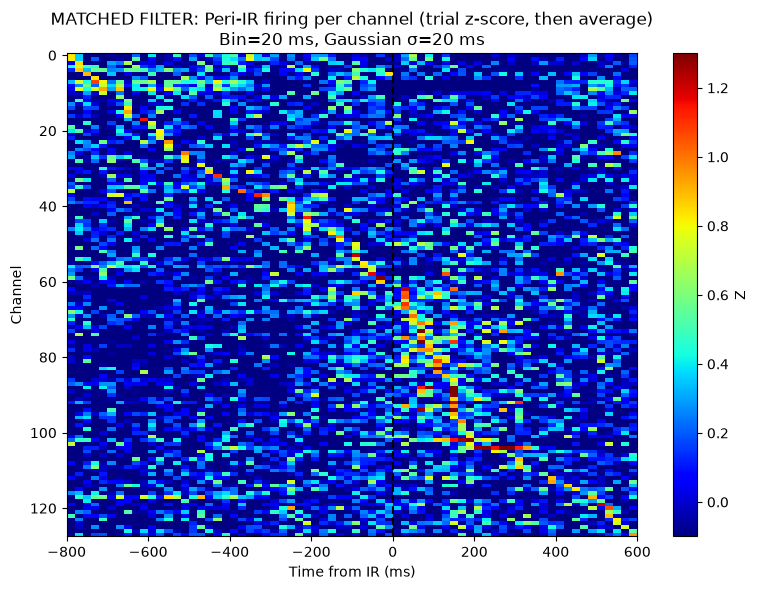

In [7]:
BIN_MS = 20
SIGMA_MS = 20
# z score per trial
mu = np.nanmean(control_counts[:, :, :], axis=2, keepdims=True)
sig = np.nanstd (control_counts[:, :, :], axis=2, keepdims=True)
sig = np.clip(sig, 1e-6, None)
counts_z = (control_counts - mu) / sig
psth_z = np.nanmean(counts_z, axis=0)
X = psth_z
t = control_rel_t

# Peak value and peak time (argmax) within the search window
X_finite = np.where(np.isfinite(X), X, -np.inf)
peak_idx = np.argmax(X_finite, axis=1)
peak_time_ms = t[peak_idx]
peak_val = np.max(X_finite, axis=1)

# Keep only neurons with a real response; rest go to bottom
z_thresh = 0  # tune (0.5–1.5 is common)
responsive = np.isfinite(peak_val) & (peak_val >= z_thresh)

order_resp = np.argsort(peak_time_ms[responsive])  # earliest first
order = np.concatenate([np.where(responsive)[0][order_resp],
                        np.where(~responsive)[0]])

psth_ch_sorted = psth_z[order]

fig, ax = plt.subplots(figsize=(8, 6))
ax.set_facecolor("0.5")
pc = ax.pcolormesh(
    control_rel_t,
    np.arange(psth_ch_sorted.shape[0]),
    psth_ch_sorted,
    shading="nearest",
    cmap="jet",
    vmin=-0.1,
    vmax=1.3,
)

ax.invert_yaxis()
ax.axvline(0, linestyle="--", color="black")
ax.set_xlabel("Time from IR (ms)")
ax.set_ylabel("Channel")
ax.set_title(f"MATCHED FILTER: Peri-IR firing per channel (trial z-score, then average)\nBin={BIN_MS} ms, Gaussian σ={SIGMA_MS} ms")
fig.colorbar(pc, ax=ax, label="Z")
plt.tight_layout()
plt.show()

In [8]:
import jax
import jax.numpy as jnp
import jax.random as jr
import equinox as eqx

from wasabi import (
    BPosterior, TrialBuffer, TrialDesign, batch_smooth_latents,
    fit_batch, fit_initial, observe_trial, init_optimizer, make_poisson_lds,
)
from wasabi.fitting import negative_loglik
from wasabi.selection import expected_final_logdets
from wasabi.utils import alignment, softplus

In [9]:
key = jr.key(0)
key1, key2 = jr.split(key, 2)

all_observations_control = jnp.array(control_counts.transpose(0, 2, 1))
num_trials, num_timesteps, n_ch = all_observations_control.shape
state_dim = 4

inputs_control = jnp.zeros((num_trials, num_timesteps, n_ch))

# keep[t] False where any channel is blanked/NaN
keep_control = jnp.all(jnp.isfinite(all_observations_control), axis=2)
observations_control = jnp.nan_to_num(all_observations_control)

E1013 17:47:12.782375 2970047 cuda_executor.cc:1348] [0] Failed to allocate device memory of 11.65GiB (12513705984 bytes): RESOURCE_EXHAUSTED: : CUDA_ERROR_OUT_OF_MEMORY: out of memory
=== Source Location Trace: ===
external/xla+/xla/stream_executor/cuda/cuda_status.cc:45
external/xla+/xla/stream_executor/cuda/cuda_device_allocator.cc:226
external/xla+/xla/stream_executor/cuda/cuda_device_allocator.cc:389

E1013 17:47:12.782454 2970047 cuda_executor.cc:1348] [0] Failed to allocate device memory of 10.49GiB (11262334976 bytes): RESOURCE_EXHAUSTED: : CUDA_ERROR_OUT_OF_MEMORY: out of memory
=== Source Location Trace: ===
external/xla+/xla/stream_executor/cuda/cuda_status.cc:45
external/xla+/xla/stream_executor/cuda/cuda_device_allocator.cc:226
external/xla+/xla/stream_executor/cuda/cuda_device_allocator.cc:389

E1013 17:47:12.782512 2970047 cuda_executor.cc:1348] [0] Failed to allocate device memory of 9.44GiB (10136100864 bytes): RESOURCE_EXHAUSTED: : CUDA_ERROR_OUT_OF_MEMORY: out of mem

In [10]:
BETA_STIM = 1.0
BETA_EMIT = 1.0

# Control trials have no stim, so B drops out and only A, C, d, Q are fit.
# V is irrelevant here; it is replaced by the spread model before the stim fit.
model_control = make_poisson_lds(
    state_dim, jnp.eye(n_ch), key2,
    mean_rate=jnp.mean(observations_control, axis=(0, 1)),
    beta_stim=BETA_STIM, beta_emit=BETA_EMIT,
)
control_buffer = TrialBuffer.empty(num_trials, num_timesteps, n_ch).extend(
    all_observations_control, inputs_control, keep_control
)
model_control, losses = fit_initial(model_control, control_buffer, num_steps=500)
print(f"NLL per bin: {losses[0]:.4f} -> {losses[-1]:.4f}")

C_fit, d_fit = model_control.observation.C, model_control.observation.d
A_fit = model_control.dynamics.A
print('singular values of A_fit:', jnp.linalg.svd(A_fit, compute_uv=False))

NLL per bin: 64.0398 -> 62.3274
singular values of A_fit: [0.9990004  0.9559077  0.89770746 0.83176166]


In [11]:
posts_control = batch_smooth_latents(
    model_control, jnp.zeros((state_dim, n_ch)), all_observations_control, inputs_control, keep_control
)

recon_control = softplus(posts_control.smoothed_means @ C_fit.T + d_fit, BETA_EMIT)
innovations_control = observations_control - recon_control

U, S, Vt = jnp.linalg.svd(C_fit, full_matrices=False)
R = Vt.T
z_control = posts_control.smoothed_means @ R

## Plots

In [12]:
import plotly.graph_objects as go
import nbformat
import plotly.io._renderers as _r
_r.nbformat = nbformat

def plot_latent_phase_portrait(conditions, alpha_trials=0.15, title=None, colorscale="Turbo"):
    """conditions: list of (label, z, centers_ms, color_or_groups)

    If the 4th element is an array of length n_trials, trials are split by
    group and one mean trace is drawn per group. Otherwise it's a color string.
    """
    import plotly.colors as pc

    fig = go.Figure()
    single = len(conditions) == 1

    for label, z, centers_ms, spec in conditions:
        z = np.asarray(z)[:, :, :3]
        ir = int(np.argmin(np.abs(centers_ms)))

        if np.ndim(spec) == 0:
            groups = np.zeros(z.shape[0], dtype=int)
            names = [label]
            colors = [spec]
        else:
            groups = np.asarray(spec)
            uniq = np.unique(groups)
            groups = np.searchsorted(uniq, groups)
            names = [f"{label} {g}" for g in uniq]
            colors = pc.sample_colorscale(colorscale, np.linspace(0, 1, len(uniq)))

        for g, (name, color) in enumerate(zip(names, colors)):
            zg = z[groups == g]

            sep = np.full((zg.shape[0], 1, 3), np.nan)
            flat = np.concatenate([zg, sep], axis=1).reshape(-1, 3)
            fig.add_trace(go.Scatter3d(
                x=flat[:, 0], y=flat[:, 1], z=flat[:, 2],
                mode="lines", line=dict(color=color, width=1),
                opacity=alpha_trials, showlegend=False,
            ))

            m = zg.mean(axis=0)
            x, y, zz = m[:, 0], m[:, 1], m[:, 2]

            fig.add_trace(go.Scatter3d(
                x=x, y=y, z=zz,
                mode="markers+lines",
                marker=dict(size=3, color=centers_ms, colorscale="Viridis",
                            showscale=False),
                line=dict(color=color, width=4),
                name=f"{name} mean",
            ))
            fig.add_trace(go.Scatter3d(
                x=[x[0]], y=[y[0]], z=[zz[0]],
                mode="markers", marker=dict(size=6, color="green"),
                name=f"{name} start",
            ))
            fig.add_trace(go.Scatter3d(
                x=[x[ir]], y=[y[ir]], z=[zz[ir]],
                mode="markers", marker=dict(size=6, color="yellow"),
                name=f"{name} IR",
            ))

    fig.update_layout(
        title=title or " vs ".join(c[0] for c in conditions) + " latent trajectories",
        scene=dict(xaxis_title="z₁", yaxis_title="z₂", zaxis_title="z₃", aspectmode="cube"),
        legend=dict(itemsizing="constant", x=1.05, y=0.5),
        margin=dict(l=0, r=0, b=0, t=40),
        width=1000, height=600,
    )
    return fig

fig = plot_latent_phase_portrait([("control", z_control, control_rel_t, "red")], alpha_trials=0.05)
fig.show()

# Batch fit on stim trials

In [13]:
import json

stim_rel_t_raw = np.load(stim_files[0])['NPRW_rel_t']

# The peristim extraction drops the blanked window rather than masking it,
# leaving a gap in the time axis. Reinsert it as NaN bins so every step is one bin.
step = float(np.median(np.diff(stim_rel_t_raw)))
gaps = np.diff(stim_rel_t_raw)
g = int(np.argmax(gaps))
n_insert = int(round(gaps[g] / step)) - 1
stim_rel_t = np.concatenate([
    stim_rel_t_raw[:g + 1],
    stim_rel_t_raw[g] + step * np.arange(1, n_insert + 1),
    stim_rel_t_raw[g + 1:],
])
n_bins_pad = len(stim_rel_t)

STIM_DUR_MS = 100.0  # confirm against nprw_meta_json
stim_bins = np.flatnonzero((stim_rel_t >= 0) & (stim_rel_t < STIM_DUR_MS))
ir_pre, ir_post = g, g + n_insert + 1

print(f"gap after {stim_rel_t_raw[g]:.0f} ms is {gaps[g]:.0f} ms -> inserted {n_insert} bins "
      f"(resumes at {stim_rel_t[ir_post]:.0f} vs actual {stim_rel_t_raw[g + 1]:.0f})")
print(f"stim spans bins {stim_bins}, pre={stim_rel_t[ir_pre]:.0f} post={stim_rel_t[ir_post]:.0f} ms")
print("control axis uniform:", bool(np.allclose(np.diff(control_rel_t), step)))

counts_list, inputs_list, s_rows = [], [], []
n_ch = None

for f in stim_files:
    npz = np.load(f, allow_pickle=True)
    counts = npz['NPRW_counts']                  # (trials, ch, bins)
    rel_t = npz['NPRW_rel_t']
    meta = json.loads(npz["nprw_meta_json"].item())
    ch0 = np.asarray(meta["stim_channels"], dtype=int) - 1

    n_tr, n_ch, n_bins = counts.shape
    if n_ch is None:
        n_ch = n_ch
    assert n_ch == n_ch, f"{f.name}: channel count mismatch"
    assert np.allclose(rel_t, stim_rel_t_raw), f"{f.name}: time axis mismatch"

    blank = np.full((n_tr, n_ch, n_insert), np.nan)
    counts_list.append(np.concatenate(
        [counts[:, :, :g + 1], blank, counts[:, :, g + 1:]], axis=2))

    s = np.zeros(n_ch)
    s[ch0] = 1.0
    u = np.zeros((n_tr, n_bins_pad, n_ch))
    u[np.ix_(np.arange(n_tr), stim_bins, ch0)] = 1.0

    inputs_list.append(u)
    s_rows.append(s)

# one spatial pattern per file, deduped and sorted by start channel
s_rows = np.stack(s_rows)
s_cand_real, block_to_cand = np.unique(s_rows, axis=0, return_inverse=True)
block_to_cand = np.asarray(block_to_cand).ravel()
order_asc = np.argsort([np.flatnonzero(s)[0] for s in s_cand_real])
s_cand_real = s_cand_real[order_asc]
block_to_cand = np.argsort(order_asc)[block_to_cand]

stim_counts = np.concatenate(counts_list, axis=0)
inputs_stim = jnp.array(np.concatenate(inputs_list, axis=0))

stim_block = np.repeat(np.arange(len(counts_list)), [c.shape[0] for c in counts_list])
cand_per_trial = block_to_cand[stim_block]

all_observations_stim = jnp.array(stim_counts.transpose(0, 2, 1))
n_trials_s, n_bins_s, n_ch_s = all_observations_stim.shape
keep_stim = jnp.all(jnp.isfinite(all_observations_stim), axis=2)
observations_stim = jnp.nan_to_num(all_observations_stim)

assert n_ch_s == n_ch
assert inputs_stim.shape == all_observations_stim.shape

print(f"{len(stim_files)} files -> {s_cand_real.shape[0]} distinct patterns")
print("channels per candidate:", [np.flatnonzero(s).tolist() for s in s_cand_real])
print("kept bins per trial:", int(keep_stim[0].sum()), "of", n_bins_pad)

gap after -30 ms is 159 ms -> inserted 7 bins (resumes at 129 vs actual 129)
stim spans bins [40 41 42 43 44], pre=-30 post=129 ms
control axis uniform: True


10 files -> 10 distinct patterns
channels per candidate: [[0, 1, 2, 3, 4, 5, 6, 7], [4, 5, 6, 7, 8, 9, 10, 11], [8, 9, 10, 11, 12, 13, 14, 15], [12, 13, 14, 15, 16, 17, 18, 19], [16, 17, 18, 19, 20, 21, 22, 23], [20, 21, 22, 23, 24, 25, 26, 27], [24, 25, 26, 27, 28, 29, 30, 31], [28, 29, 30, 31, 32, 33, 34, 35], [32, 33, 34, 35, 36, 37, 38, 39], [36, 37, 38, 39, 40, 41, 42, 43]]
kept bins per trial: 63 of 70


In [14]:
width = 3.0
V_stim = jnp.array(make_toeplitz_V(n_ch, width))

# Start from the control fit with the spread model, then batch EM over the stim trials:
# E-step = joint EKF over [x; vec(B)] across all trials, M-step = refit A, C, d, Q, b
model_init = eqx.tree_at(lambda m: m.dynamics.V, model_control, V_stim)
stim_buffer = TrialBuffer.empty(n_trials_s, n_bins_s, n_ch).extend(
    all_observations_stim, inputs_stim, keep_stim
)
model_stim, B_post, em_losses = fit_batch(
    model_init, BPosterior.from_prior(state_dim, n_ch, prior_var=1.0), stim_buffer,
    num_iters=10, refit_steps=50,
)
print("NLL per bin by EM iteration:", np.round(np.asarray(em_losses[:, -1]), 4))

C_fit_s, d_fit_s = model_stim.observation.C, model_stim.observation.d
A_fit_s, b_fit_s = model_stim.dynamics.A, model_stim.dynamics.b
B_fit_s = B_post.B
print(f"|B|={float(jnp.linalg.norm(B_fit_s)):.4f}  b={float(b_fit_s):.3f}")
print('singular values of A_fit_s:', jnp.linalg.svd(A_fit_s, compute_uv=False))

NLL per bin by EM iteration: [65.5919 64.8026 64.5315 64.3559 64.2451 64.1695 64.1176 64.0838 64.0581
 64.0361]
|B|=3.5839  b=-0.248
singular values of A_fit_s: [0.9990007 0.9990004 0.9945302 0.9256575]


In [15]:
posts_stim = batch_smooth_latents(model_stim, B_fit_s, all_observations_stim, inputs_stim, keep_stim)

recon_stim = softplus(posts_stim.smoothed_means @ C_fit_s.T + d_fit_s, BETA_EMIT)
innovations_stim = observations_stim - recon_stim

rot, rot_inv = alignment(C_fit, C_fit_s)
z_stim = (posts_stim.smoothed_means @ rot) @ R

fig = plot_latent_phase_portrait(
    [("stim", z_stim, stim_rel_t, stim_block)],
    alpha_trials=0.03,
)
fig.show()

In [16]:
fig = plot_latent_phase_portrait(
    [("control", z_control, control_rel_t, "red"),
    ("stim", z_stim, stim_rel_t, stim_block)],
    alpha_trials=0.03,
)
fig.update_layout(scene_camera=dict(
    eye=dict(x=1.75, y=0.75, z=0.75),
    center=dict(x=0, y=0, z=-0.2),
))
fig.show()

# Fit via WASABI vs Tile (sequentially)

Replays the recorded stim trials one at a time. Each strategy picks a pattern among those
with trials left, then a recorded trial of that pattern is fed to the joint EKF, which
updates the posterior over B. The dynamics are held at the batch fit so the strategies
differ only in the order they see the data. Held-out NLL is the predictive negative log
likelihood per bin of a held-out quarter of each pattern's trials, under the posterior mean of B.

In [17]:
K, N = state_dim, n_ch
n_cand = len(s_cand_real)
design = TrialDesign(keep_stim[0], int(stim_bins[0]), len(stim_bins))
assert bool(jnp.all(keep_stim == keep_stim[0])), "replay assumes one blanking window"
print("blanked bins:", np.flatnonzero(~np.asarray(design.keep)))

# hold out a quarter of each pool for predictive error
rng = np.random.default_rng(0)
pools, test_parts = [], []
for j in range(n_cand):
    idx = rng.permutation(np.flatnonzero(cand_per_trial == j))
    n_test = max(1, len(idx) // 4)
    test_parts.append(idx[:n_test])
    pools.append(idx[n_test:].tolist())
test_idx = np.concatenate(test_parts)
print("pool sizes:", [len(p) for p in pools], "| held out:", len(test_idx))

test_buffer = TrialBuffer.empty(len(test_idx), n_bins_s, n_ch).extend(
    all_observations_stim[test_idx], inputs_stim[test_idx], keep_stim[test_idx]
)
prior_var = float((np.asarray(B_fit_s) ** 2).mean())  # scale of the batch-fit B

# Ordering tiling
starts = np.array([np.flatnonzero(s)[0] for s in s_cand_real])
coarse = np.flatnonzero(starts % 8 == 0)
fine = np.flatnonzero(starts % 8 != 0)
tile_order = np.concatenate([coarse, fine])

def heldout_nll(prior):
    return float(negative_loglik(model_stim, prior.B, test_buffer))

def replay(mode, seed=0):
    rng = np.random.default_rng(seed)
    avail = [rng.permutation(pool).tolist() for pool in pools]
    prior = BPosterior.from_prior(K, N, prior_var)
    buffer = TrialBuffer.empty(sum(map(len, pools)), n_bins_s, n_ch)
    optimizer, opt_state = init_optimizer(model_stim)
    errs, lds, order = [heldout_nll(prior)], [float(prior.logdet())], []
    t = 0
    while any(avail):
        curr_cand_idx = [k for k in range(n_cand) if avail[k]]
        if mode == "D_opt":
            scores = expected_final_logdets(model_stim, prior, s_cand_real[curr_cand_idx], design)
            chosen = curr_cand_idx[int(jnp.argmin(scores))]
        elif mode == "tile":
            chosen = curr_cand_idx[t % len(curr_cand_idx)]
        elif mode == "tile_coarse_fine":
            cyc = [k for k in tile_order if k in curr_cand_idx]
            chosen = cyc[t % len(cyc)]
        else:
            chosen = curr_cand_idx[rng.integers(len(curr_cand_idx))]
        i = avail[chosen].pop()  # remove this used trial from the avail list
        _, prior, buffer, opt_state, _ = observe_trial(
            model_stim, prior, buffer, optimizer, opt_state,
            all_observations_stim[i], inputs_stim[i], keep_stim[i], refit_steps=0,
        )
        order.append(chosen)
        lds.append(float(prior.logdet()))
        errs.append(heldout_nll(prior))
        t += 1
    return map(np.asarray, (errs, lds, order)), prior

n_seeds = 20
MODES = ("D_opt", "tile_coarse_fine", "random")  # "tile",
curves, logdet, selected, posteriors = {}, {}, {}, {}
for mode in MODES:
    e, l, sel, ps = [], [], [], []
    for seed in range(n_seeds):
        (err, ld, order), prior = replay(mode, seed)
        e.append(err); l.append(ld); sel.append(order); ps.append(prior)
    curves[mode], logdet[mode], selected[mode], posteriors[mode] = np.vstack(e), np.vstack(l), np.vstack(sel), ps
    print(f"{mode}: heldout NLL/bin {curves[mode][:, -1].mean():.4f} (start {curves[mode][:, 0].mean():.4f})  "
          f"logdet drop {logdet[mode][:, 0].mean() - logdet[mode][:, -1].mean():.1f} nats")
print(f"batch-fit B: heldout NLL/bin {float(negative_loglik(model_stim, B_fit_s, test_buffer)):.4f} (fit on all trials, incl. held out)")

blanked bins: [39 40 41 42 43 44 45]
pool sizes: [6, 3, 6, 6, 8, 7, 6, 4, 5, 6] | held out: 15


D_opt: heldout NLL/bin 62.7029 (start 62.7328)  logdet drop 20.8 nats


tile_coarse_fine: heldout NLL/bin 62.7029 (start 62.7328)  logdet drop 20.8 nats


random: heldout NLL/bin 62.7029 (start 62.7328)  logdet drop 20.8 nats
batch-fit B: heldout NLL/bin 62.6942 (fit on all trials, incl. held out)


Text(0.5, 1.0, 'B (batch EM posterior mean)')

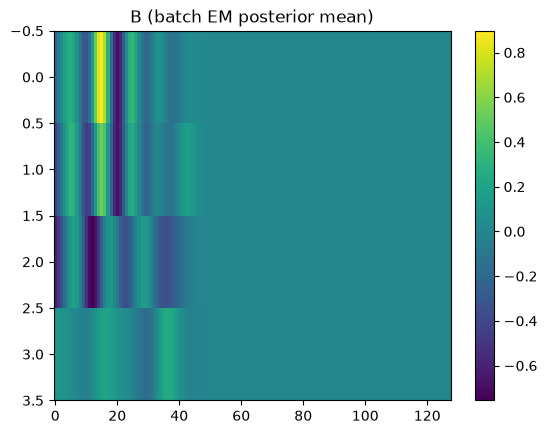

In [18]:
plt.imshow(B_fit_s, aspect='auto'); plt.colorbar(); plt.title('B (batch EM posterior mean)')

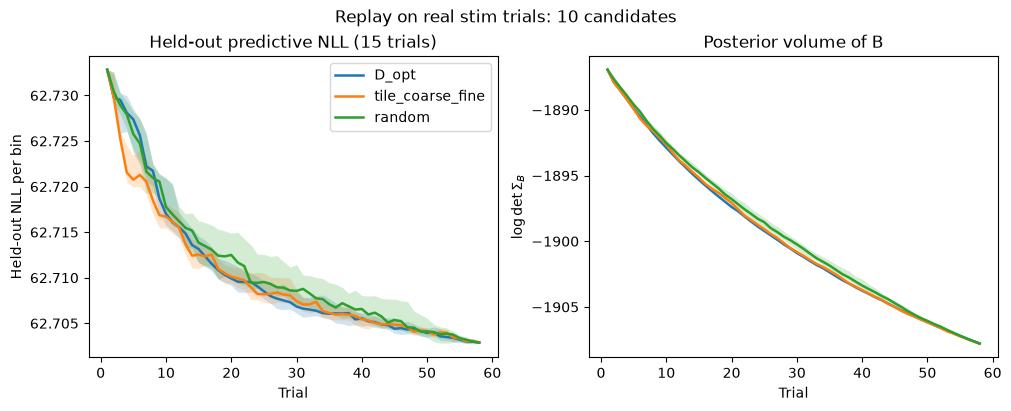

In [19]:
n_steps = curves["D_opt"].shape[1]
trials = np.arange(1, n_steps + 1)

fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)


for mode in MODES:
    for ax, data, ylab in (
        (axes[0], curves[mode], "Held-out NLL per bin"),
        (axes[1], logdet[mode],     r"$\log\det \Sigma_B$"),
    ):
        lo, med, hi = np.percentile(data, [25, 50, 75], axis=0)
        line = ax.plot(trials, med, lw=1.8, label=mode)[0]
        ax.fill_between(trials, lo, hi, color=line.get_color(), alpha=0.2, lw=0)
        ax.set_xlabel("Trial")
        ax.set_ylabel(ylab)

axes[0].legend()
axes[0].set_title(f"Held-out predictive NLL ({len(test_idx)} trials)")
axes[1].set_title("Posterior volume of B")
fig.suptitle(f"Replay on real stim trials: {n_cand} candidates")
plt.show()

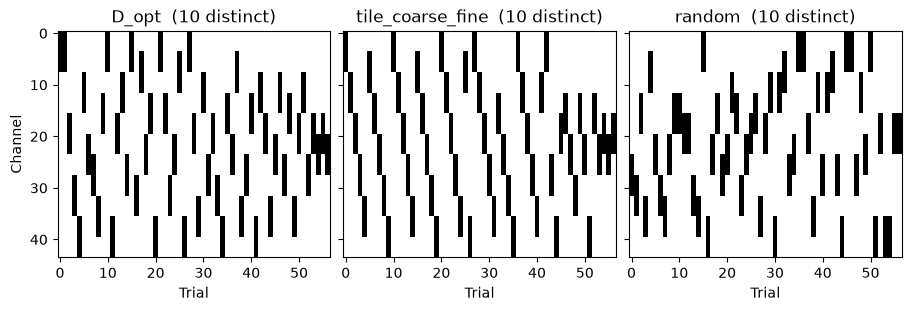

In [20]:
seed_show = 0
n_steps = selected["D_opt"].shape[1]

fig, axes = plt.subplots(1, len(MODES), figsize=(3 * len(MODES), 3),
                         constrained_layout=True, sharey=True)

for ax, mode in zip(axes, MODES):
    js = selected[mode][seed_show]

    # expand candidate index to its stim channels
    S_sel = s_cand_real[js]  # (n_steps, n_ch)
    ax.imshow(S_sel.T, aspect="auto", interpolation="nearest",
              vmin=0, vmax=1, cmap="Greys")
    ax.set_title(f"{mode}  ({len(np.unique(js))} distinct)")
    ax.set_xlabel("Trial")

axes[0].set_ylim(43.5, -0.5)
axes[0].set_ylabel("Channel")
plt.show()

## Simulation

The simulated comparison of D-optimal, tile and random selection that used to live here
is now `scripts/joint_ekf_simulation.py`.